# Practical No. 04: Image Generation using Deep Convolutional GAN (DCGAN)

**Aim:** Implement and train a Deep Convolutional Generative Adversarial Network (DCGAN) using the **Fashion-MNIST** dataset, generate synthetic images, and evaluate the model using Generator/Discriminator loss curves and visual inspection.

**Dataset:** Fashion-MNIST contains 70,000 grayscale clothing images across 10 categories. Each image is 28 × 28 pixels. This dataset is smaller and faster to process than CIFAR-10, making it suitable for a quick practical implementation.

**DCGAN working:** The Generator converts random latent vectors into synthetic images. The Discriminator learns to distinguish real dataset images from generated images. Both networks are trained alternately.



Submitted by :

PRN : 202502110008

Name : Dhanashri Abhijit Shah

## 1. Import libraries and configure settings

For faster execution, this notebook uses a subset of Fashion-MNIST and a small number of epochs. Google Colab GPU is recommended, but CPU execution is also possible.

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42
tf.keras.utils.set_random_seed(SEED)

LATENT_DIM = 100
BATCH_SIZE = 128
EPOCHS = 8
TRAIN_LIMIT = 12000

TensorFlow version: 2.21.0
Available GPU: []


## 2. Load and preprocess Fashion-MNIST

Fashion-MNIST images are grayscale and have dimensions 28 × 28. We add a channel dimension to make the input shape 28 × 28 × 1. Pixel values are normalized to `[-1, 1]` because the Generator uses a `tanh` output layer.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training data shape: (12000, 28, 28, 1)
Pixel range: -1.0 to 1.0


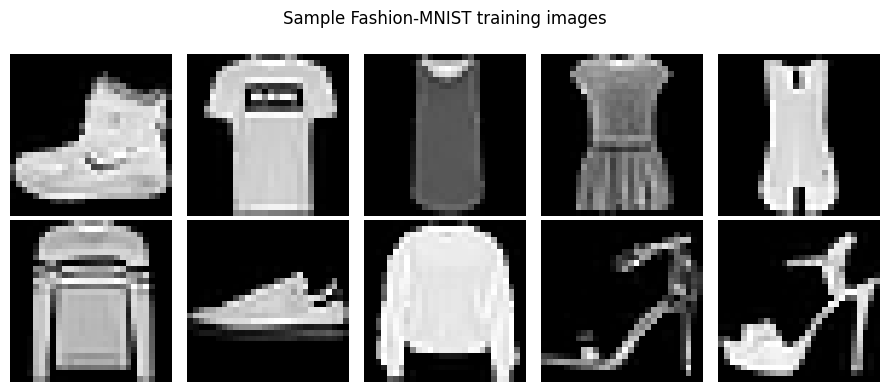

In [2]:
(x_train, _), (x_test, _) = tf.keras.datasets.fashion_mnist.load_data()

x_train = x_train[:TRAIN_LIMIT].astype("float32")
x_train = (x_train - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

print("Training data shape:", x_train.shape)
print("Pixel range:", float(x_train.min()), "to", float(x_train.max()))

fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for ax, image in zip(axes.flat, x_train[:10]):
    ax.imshow(image.squeeze(), cmap="gray", vmin=-1, vmax=1)
    ax.axis("off")
plt.suptitle("Sample Fashion-MNIST training images")
plt.tight_layout()
plt.show()

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(TRAIN_LIMIT, seed=SEED)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

## 3. Build the Generator

The Generator receives a 100-dimensional random vector. A Dense layer reshapes it into a 7 × 7 feature map, and transposed convolution layers upsample it to a 28 × 28 grayscale image.

In [3]:
def build_generator(latent_dim=LATENT_DIM):
    model = tf.keras.Sequential(name="Generator")
    model.add(layers.Input(shape=(latent_dim,)))
    model.add(layers.Dense(7 * 7 * 128, use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Reshape((7, 7, 128)))

    model.add(layers.Conv2DTranspose(
        64, kernel_size=4, strides=2, padding="same", use_bias=False
    ))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(negative_slope=0.2))

    model.add(layers.Conv2DTranspose(
        1, kernel_size=4, strides=2, padding="same", activation="tanh"
    ))
    return model

generator = build_generator()
generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 784,641 (2.99 MB)

 Trainable params: 771,969 (2.94 MB)

 Non-trainable params: 12,672 (49.50 KB)

## 4. Build the Discriminator

The Discriminator is a Convolutional Neural Network (CNN). It extracts features from a 28 × 28 grayscale image and outputs one logit representing whether the image is real or generated.

In [4]:
def build_discriminator():
    model = tf.keras.Sequential(name="Discriminator")
    model.add(layers.Input(shape=(28, 28, 1)))

    model.add(layers.Conv2D(64, kernel_size=4, strides=2, padding="same"))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, kernel_size=4, strides=2, padding="same"))
    model.add(layers.LeakyReLU(negative_slope=0.2))
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1))  # logits
    return model

discriminator = build_discriminator()
discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Define loss functions and optimizers

Binary cross-entropy is used for adversarial training. The Discriminator learns to classify real images as 1 and generated images as 0. The Generator tries to make generated images classified as real (1).

In [5]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

@tf.function
def train_step(real_images):
    noise = tf.random.normal([BATCH_SIZE, LATENT_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gen_gradients = gen_tape.gradient(gen_loss, generator.trainable_variables)
    disc_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gen_gradients, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(disc_gradients, discriminator.trainable_variables))
    return gen_loss, disc_loss

## 6. Train the DCGAN

A fixed collection of random latent vectors is used to display generated images after selected epochs. This makes it easier to compare how image quality changes during training.

Epoch 1/8 | Generator loss: 0.8848 | Discriminator loss: 0.9325 | Time: 76.0s


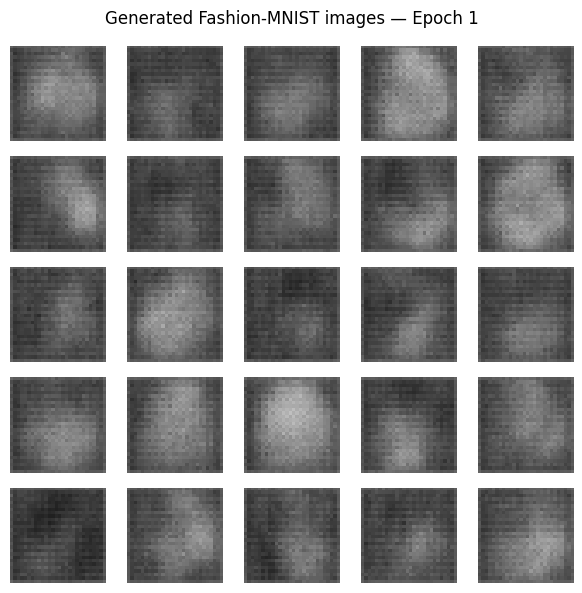

Epoch 2/8 | Generator loss: 0.7622 | Discriminator loss: 1.2973 | Time: 62.3s


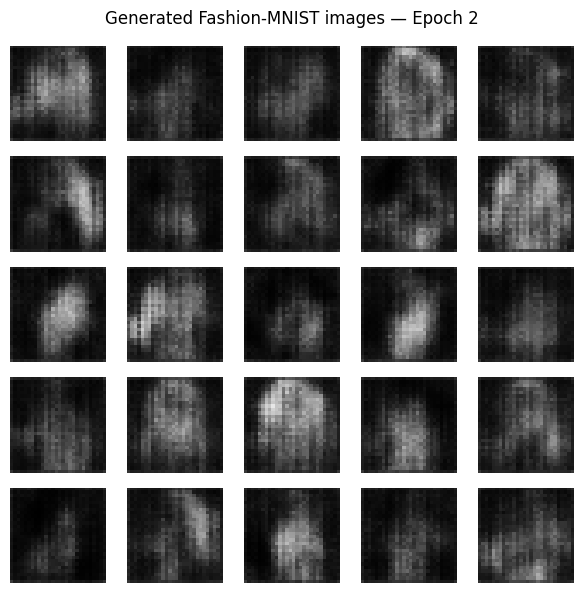

Epoch 3/8 | Generator loss: 0.7488 | Discriminator loss: 1.3400 | Time: 64.4s
Epoch 4/8 | Generator loss: 0.7460 | Discriminator loss: 1.3378 | Time: 62.8s


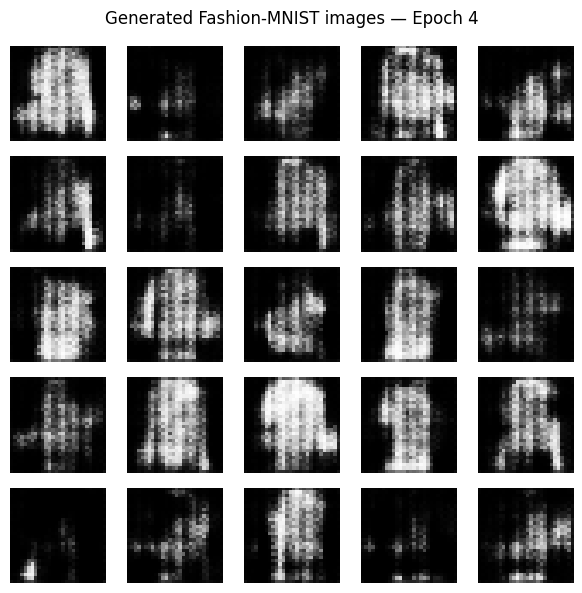

Epoch 5/8 | Generator loss: 0.7631 | Discriminator loss: 1.3086 | Time: 81.9s
Epoch 6/8 | Generator loss: 0.7894 | Discriminator loss: 1.2747 | Time: 66.0s


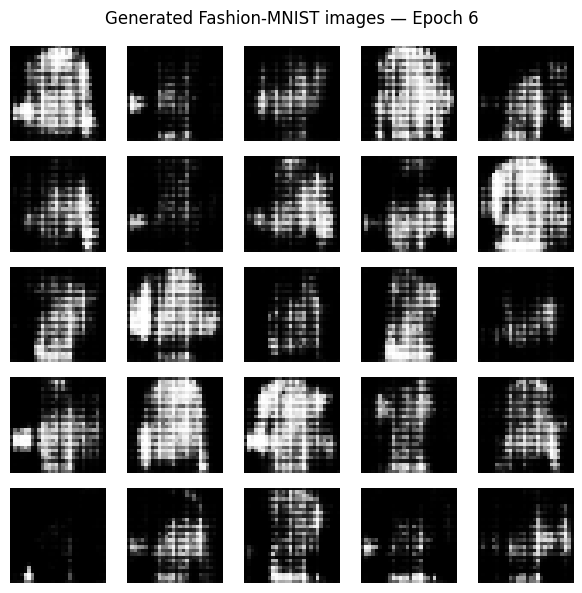

Epoch 7/8 | Generator loss: 0.8432 | Discriminator loss: 1.2111 | Time: 81.9s
Epoch 8/8 | Generator loss: 0.8744 | Discriminator loss: 1.1766 | Time: 81.9s


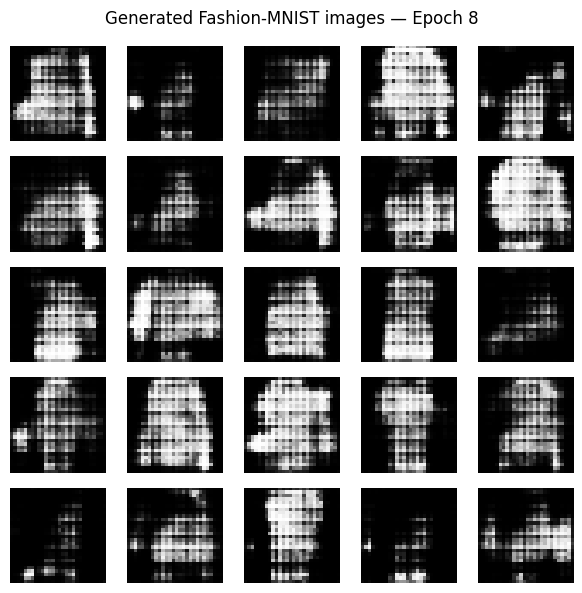

In [6]:
NUM_EXAMPLES = 25
fixed_noise = tf.random.normal([NUM_EXAMPLES, LATENT_DIM])

generator_losses = []
discriminator_losses = []

def show_generated_images(epoch):
    generated = generator(fixed_noise, training=False)
    generated = (generated + 1.0) / 2.0

    fig, axes = plt.subplots(5, 5, figsize=(6, 6))
    for ax, image in zip(axes.flat, generated):
        ax.imshow(tf.squeeze(image), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    plt.suptitle(f"Generated Fashion-MNIST images — Epoch {epoch}")
    plt.tight_layout()
    plt.show()

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()
    g_metric = tf.keras.metrics.Mean()
    d_metric = tf.keras.metrics.Mean()

    for real_batch in train_dataset:
        g_loss, d_loss = train_step(real_batch)
        g_metric.update_state(g_loss)
        d_metric.update_state(d_loss)

    g_value = float(g_metric.result())
    d_value = float(d_metric.result())
    generator_losses.append(g_value)
    discriminator_losses.append(d_value)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Generator loss: {g_value:.4f} | "
        f"Discriminator loss: {d_value:.4f} | "
        f"Time: {time.time() - start_time:.1f}s"
    )

    if epoch == 1 or epoch % 2 == 0 or epoch == EPOCHS:
        show_generated_images(epoch)

## 7. Plot Generator and Discriminator loss curves

GAN losses often fluctuate because the Generator and Discriminator are competing. They do not always decrease smoothly. Interpret the curves together with the generated image samples.

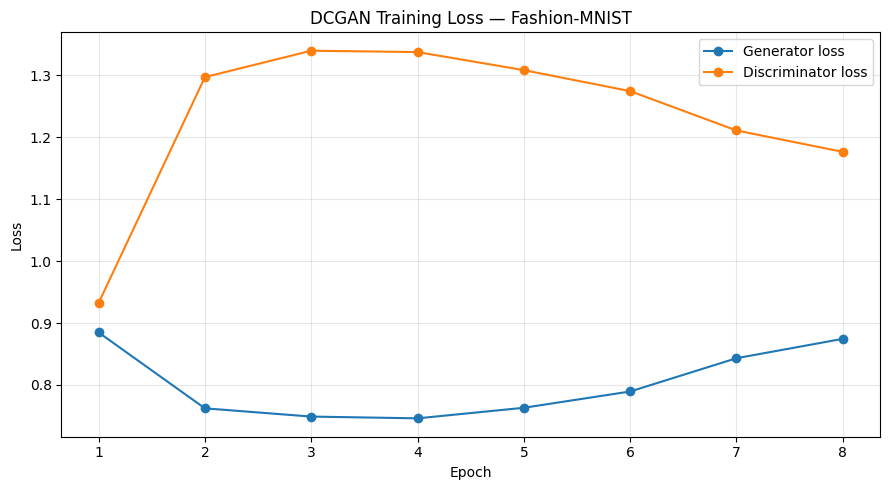

In [7]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, EPOCHS + 1), generator_losses, marker="o", label="Generator loss")
plt.plot(range(1, EPOCHS + 1), discriminator_losses, marker="o", label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Training Loss — Fashion-MNIST")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Generate new synthetic images

After training, new random latent vectors are passed to the Generator. The output is displayed as a grid of synthetic grayscale clothing images.

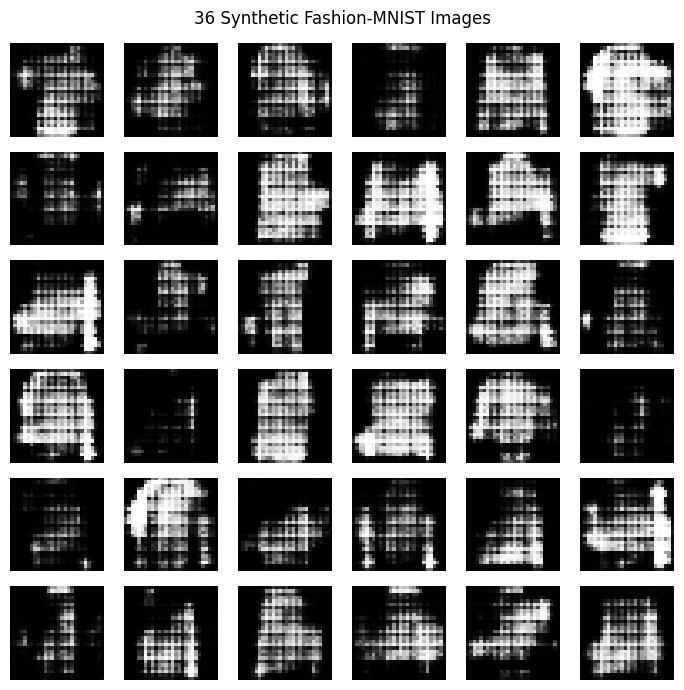

In [8]:
number_of_images = 36
random_noise = tf.random.normal([number_of_images, LATENT_DIM])
generated_images = generator(random_noise, training=False)
generated_images = (generated_images + 1.0) / 2.0

fig, axes = plt.subplots(6, 6, figsize=(7, 7))
for ax, image in zip(axes.flat, generated_images):
    ax.imshow(tf.squeeze(image), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("36 Synthetic Fashion-MNIST Images")
plt.tight_layout()
plt.show()

## 9. Evaluate the Discriminator and save the models

The following comparison checks how often the Discriminator labels held-out real images as real and generated images as fake. This is a diagnostic, not a standalone image-quality metric. A strong visual assessment should also examine diversity, recognizable clothing shapes, and artefacts.

In [9]:
real_test = (x_test[:256].astype("float32") - 127.5) / 127.5
real_test = np.expand_dims(real_test, axis=-1)
fake_test = generator(tf.random.normal([256, LATENT_DIM]), training=False)

real_logits = discriminator(real_test, training=False)
fake_logits = discriminator(fake_test, training=False)

real_acc = tf.reduce_mean(tf.cast(tf.sigmoid(real_logits) >= 0.5, tf.float32))
fake_acc = tf.reduce_mean(tf.cast(tf.sigmoid(fake_logits) < 0.5, tf.float32))

print(f"Discriminator real-image accuracy: {float(real_acc) * 100:.2f}%")
print(f"Discriminator generated-image accuracy: {float(fake_acc) * 100:.2f}%")

generator.save("dcgan_fashion_mnist_generator.keras")
discriminator.save("dcgan_fashion_mnist_discriminator.keras")
print("Generator and Discriminator models saved successfully.")

Discriminator real-image accuracy: 81.64%
Discriminator generated-image accuracy: 100.00%
Generator and Discriminator models saved successfully.


## 10. Result, observations, and conclusion

**Result:** A Deep Convolutional GAN was implemented and trained using the Fashion-MNIST dataset. The Generator produced synthetic 28 × 28 grayscale clothing images from random latent vectors. Generator and Discriminator loss curves were plotted to observe adversarial training.

**Observations to record after running:**
1. At the beginning, generated images may look like random noise.
2. As training progresses, the Generator may learn clothing-like outlines and textures.
3. Generator and Discriminator losses may fluctuate as both networks improve against each other.
4. If the Discriminator becomes too strong, the Generator may struggle to fool it. If the Generator produces similar-looking images repeatedly, this may indicate mode collapse.
5. Since this is a short training run on a subset of the data, some generated images may be unclear. More epochs can improve results but increase execution time.

**Conclusion:** DCGAN uses adversarial training between a Generator and a Discriminator to learn the distribution of real Fashion-MNIST images. The trained Generator can create new synthetic clothing images. Loss curves and visual inspection together help evaluate the model's training behaviour and generated-image quality.

**Important:** Report the actual loss values and observations produced by your run. Do not claim a specific accuracy or perfect image quality unless measured.